# 04 Results: Isolation Forest on the DNS tunnel data (slice 4 and 5)

One notebook, top to bottom: the main setup, the main result, the comparison with simple rules, what the alerts look like as incidents, three checks (alert line and window, robustness and stress tests, errors) and the takeaways. All modelling code is in `src/` (`detector.py`, `evaluation.py`, `baselines.py`, `incidents.py`, `variants.py`, `plots.py`); this notebook only sets things up, calls it and shows the results. Figures are saved in `notebooks/figures/`.

Run time is about 2 to 3 minutes. Needs `data/raw/dns.log` (Canvas download); it builds the features itself, so `python main.py` is not required.

**How to read the numbers.** There is one tunnel session and one benign client, so everything here is optimistic and none of it proves generalisation. ROC and PR AUC do not depend on the alert line; precision, recall and the false positives do. Seeds only vary the random forest, not the data.

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image, display
from sklearn.metrics import roc_auc_score, average_precision_score, precision_recall_curve, roc_curve

warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.features import make_matrix, build_features, feature_sets
from src.prepare import load_raw, prepare
from src.detector import run_detector, DEFAULTS
from src.evaluation import confusion, recall_per_phase, feature_importance, plot_score_distribution
from src.incidents import group_alerts, incident_metrics
from src.baselines import run_rule
from src.variants import slow_tunnel, add_benign_clients, inject_repeats
from src.plots import plot_isolation_view

FIG = ROOT / "notebooks" / "figures"
FIG.mkdir(exist_ok=True)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

## 1. The main setup and the main result

In [2]:
WINDOW, THRESHOLD, SEEDS = 60, "folds_median", list(range(10))
FEATURES = feature_sets(WINDOW)["forced"]

pd.Series({
    "model": f"Isolation Forest, {DEFAULTS['n_estimators']} trees, 256 rows per tree",
    "features": ", ".join(FEATURES),
    "window": f"{WINDOW} s",
    "training": "normal traffic only, before 18:30 UTC: first 80% fits the forest (the last 20% is a time-ordered check slice)",
    "alert line": "median of five lines: training is cut into 5 consecutive pieces, each held back once; its highest normal score is that piece's line (folds_median)",
    "test": "everything from 18:30 UTC (contains the tunnel session)",
    "seeds": f"{len(SEEDS)} (0 to {SEEDS[-1]}); mean and spread are reported, never the best seed",
}, name="setup").to_frame()

,setup
model,"Isolation Forest, 300 trees, 256 rows per tree"
features,"name_bytes, uniq_names_60s, uniq_ratio_60s, no..."
window,60 s
training,"normal traffic only, before 18:30 UTC: first 8..."
alert line,median of five lines: training is cut into 5 c...
test,everything from 18:30 UTC (contains the tunnel...
seeds,"10 (0 to 9); mean and spread are reported, nev..."


In [3]:
m = make_matrix(session="second", window_s=WINDOW, write=False)
print(m.groupby(["split", "label"]).size().unstack(fill_value=0))


def metrics(scored):
    """Everything we report for one scored table (test rows only)."""
    t = scored[scored.role == "test"]
    return {"roc_auc": roc_auc_score(t.y, t.score), "pr_auc": average_precision_score(t.y, t.score),
            **confusion(t.y, t.alert), **incident_metrics(scored)}


runs = {s: run_detector(m, FEATURES, threshold=THRESHOLD, random_state=s) for s in SEEDS}
main = pd.DataFrame({s: metrics(sc) for s, (sc, info) in runs.items()}).T
COLS = ["roc_auc", "pr_auc", "precision", "recall", "f1", "fpr", "fp", "fn", "false_incidents", "seconds_to_first_alert"]
headline = main[COLS].astype(float).agg(["mean", "std", "min", "max"]).T.round(3)
headline

label  benign  tunnel
split                
test     1609     222
train    1592       0


,mean,std,min,max
roc_auc,0.996,0.000,0.995,0.996
pr_auc,0.993,0.000,0.992,0.994
precision,0.744,0.024,0.693,0.774
recall,0.987,0.001,0.986,0.991
f1,0.848,0.016,0.814,0.867
fpr,0.047,0.006,0.040,0.060
fp,75.600,9.686,64.000,97.000
fn,2.900,0.316,2.000,3.000
false_incidents,3.600,1.075,3.000,6.000
seconds_to_first_alert,0.007,0.000,0.007,0.007


### Summary: Isolation Forest Detection Results

Isolation Forest achieves strong detection performance on the test dataset containing 1,609 benign queries and 222 tunnel queries.

Across ten random seeds, the model achieves a mean ROC AUC of 0.996, PR AUC of 0.993, recall of 98.7%, and precision of 74.4%.

On average, approximately 219 of the 222 tunnel queries are detected, while 76 benign queries are incorrectly flagged.

The high PR AUC indicates that the model separates tunnel and benign traffic very well. However, the lower precision shows that the current alert threshold still generates a considerable number of false positives.

These false positives are grouped into approximately 3.6 incidents per run, which may reduce the operational workload.

The reported time to first alert is 0.007 seconds, but its exact definition needs verification before interpreting it as detection latency.

The main improvement opportunity is to investigate threshold calibration and false-positive behaviour without using test labels for model tuning.

Seed 0 is the default run in `python -m src.detector`; it is shown in detail below, but it is one of ten seeds and not the best.

alert line (seed 0): 0.6796


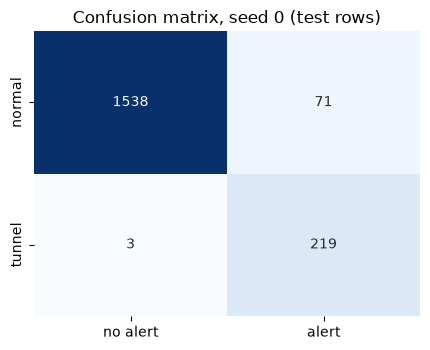

,queries,detected,recall
phase,,,
data,24,24,1.000
encoding_test,9,8,0.889
handshake,3,1,0.333
ping,173,173,1.000
size_probe,13,13,1.000


In [4]:
scored0, info0 = runs[0]
t0 = scored0[scored0.role == "test"]
print(f"alert line (seed 0): {info0['threshold']:.4f}")

c0 = confusion(t0.y, t0.alert)
cm = np.array([[c0["tn"], c0["fp"]], [c0["fn"], c0["tp"]]])
fig, ax = plt.subplots(figsize=(4.4, 3.6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
            xticklabels=["no alert", "alert"], yticklabels=["normal", "tunnel"])
ax.set_title("Confusion matrix, seed 0 (test rows)")
plt.tight_layout(); plt.savefig(FIG / "confusion_matrix.png", dpi=150); plt.show()
recall_per_phase(t0).round(3)

### Summary: Confusion Matrix and Detection by Tunnel Phase

For random seed 0, Isolation Forest correctly detects 219 of the 222 tunnel queries and incorrectly flags 71 of the 1,609 benign queries.

This results in a recall of 98.65%, precision of 75.52%, and a false-positive rate of 4.41%.

The three missed tunnel queries occur during the early stages of the session: two handshake queries and one encoding-test query.

All ping queries, data queries, and size probes are successfully detected. This confirms that behavioural features are effective even when individual DNS queries resemble normal traffic.

The alert threshold for this run is 0.6796. Further analysis should focus on reducing false positives and verifying the exact time and query number of the first tunnel alert.

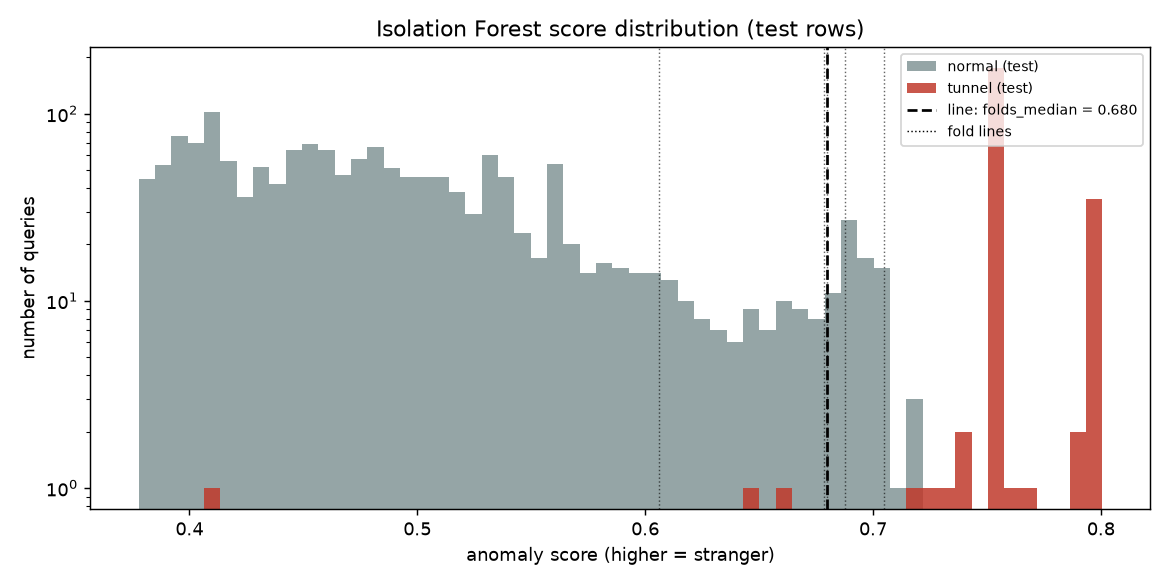

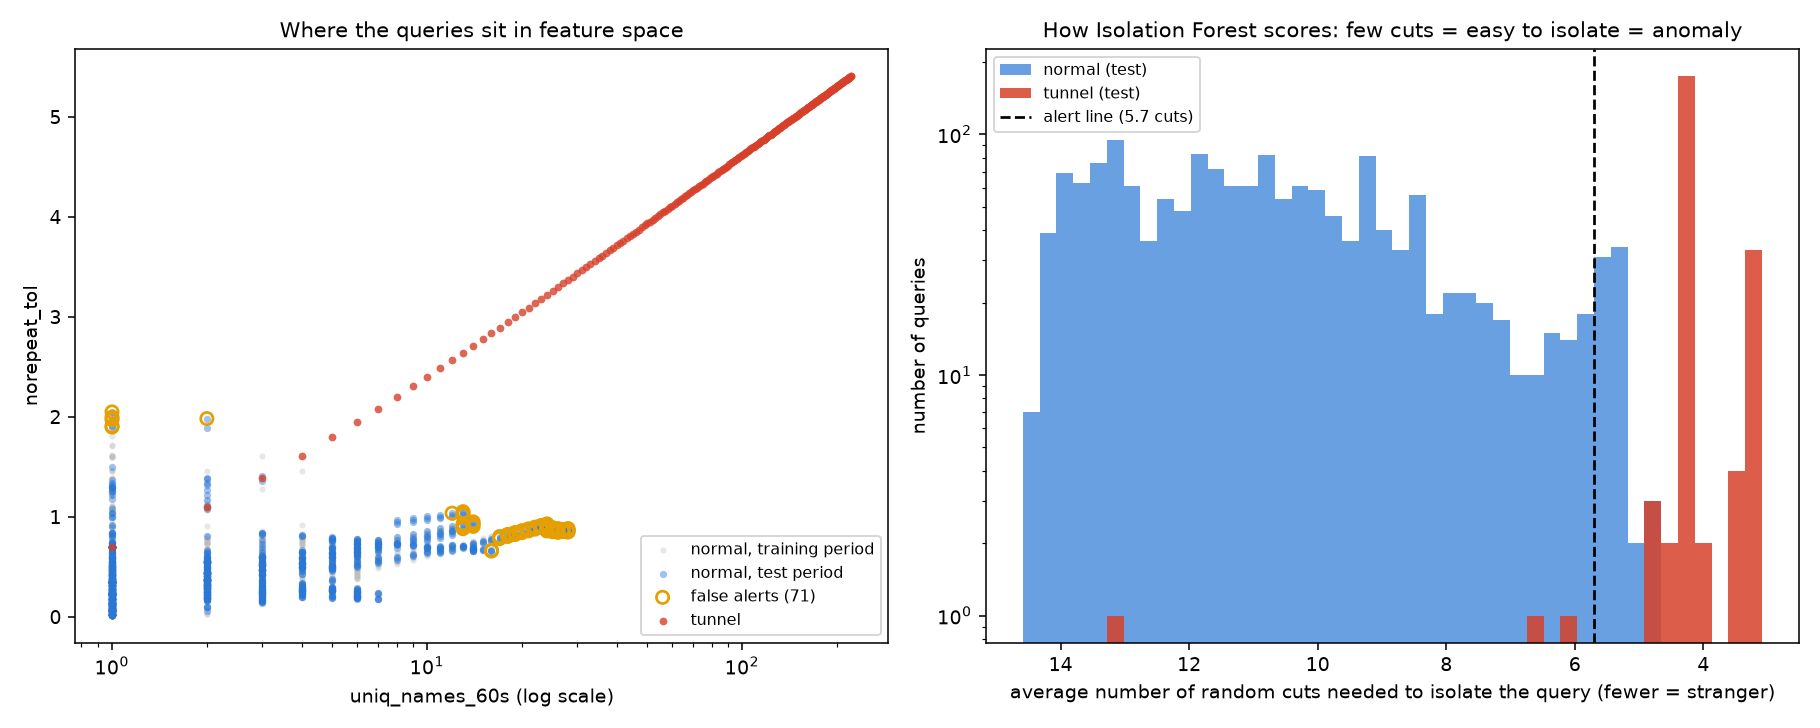

In [5]:
display(Image(filename=str(plot_score_distribution(scored0, info0, FIG / "score_distribution.png"))))
display(Image(filename=str(plot_isolation_view(scored0, info0, FIG / "isolation_forest_view.png"))))

### Summary: Isolation Forest Scores and False Positives

The anomaly score distribution shows that Isolation Forest separates most tunnel queries from benign DNS traffic.

Tunnel queries generally receive higher anomaly scores, while most benign queries remain below the alert threshold of approximately 0.680.

The feature-space visualisation shows that the 71 false positives are concentrated in specific regions. Some have unusually high numbers of unique DNS names, while others have relatively high no-repeat tolerance values despite low query counts.

These patterns are consistent with the unusual benign behaviour previously observed for Yahoo and Azure, although the responsible domains still need to be verified.

The final graph illustrates the Isolation Forest principle: unusual queries require fewer random splits to isolate and therefore receive higher anomaly scores.

The next step is to identify the domains responsible for false positives and investigate whether alert calibration can be improved without reducing tunnel recall.

In [6]:
imp = feature_importance(info0["model"], t0[FEATURES], t0.y.to_numpy())
fig, ax = plt.subplots(figsize=(6.5, 2.6))
imp.sort_values().plot.barh(ax=ax, color="#2a78d6")
ax.set_xlabel("PR AUC drop when the feature is shuffled (explains the model; not used to choose features)")
plt.tight_layout(); plt.savefig(FIG / "feature_importance.png", dpi=150); plt.show()
imp.round(3).to_frame()

,PR AUC drop
uniq_names_60s,0.342
norepeat_tol,0.200
name_bytes,0.007
uniq_ratio_60s,0.004


### Summary: Feature Importance Analysis

The feature importance analysis shows that `uniq_names_60s` and `norepeat_tol` contribute most strongly to DNS tunnel detection.

Disrupting `uniq_names_60s` reduces PR AUC by 0.342, while disrupting `norepeat_tol` reduces it by 0.200.

In contrast, `name_bytes` and `uniq_ratio_60s` have much smaller effects, with PR AUC drops of 0.007 and 0.004.

These results confirm that behavioural patterns are more important than individual DNS query characteristics.

A simpler model using only the two strongest features could be investigated. However, feature importance alone is not sufficient to justify removing features, and any new configuration requires separate validation.

## 2. Against simple rules

A rule has nothing to fit: it scores each query with one number and alerts when that number is higher than anything seen in normal training traffic. **Unique names** uses `uniq_names_60s`; **name shape** alerts on a longer or more random-looking name than in training. The Isolation Forest row is the mean of the seeds.

In [7]:
rules = {"rule: unique names": run_rule(m, "unique_names", WINDOW),
         "rule: name shape": run_rule(m, "shape", WINDOW)}
rows = {f"Isolation Forest (mean of {len(SEEDS)} seeds)": main[COLS].astype(float).mean()}
for name, sc in rules.items():
    rows[name] = pd.Series(metrics(sc))[COLS]
compare = pd.DataFrame(rows).T.astype(float).round(3)
compare

,roc_auc,pr_auc,precision,recall,f1,fpr,fp,fn,false_incidents,seconds_to_first_alert
Isolation Forest (mean of 10 seeds),0.996,0.993,0.744,0.987,0.848,0.047,75.6,2.9,3.6,0.007
rule: unique names,0.987,0.958,0.798,0.928,0.858,0.032,52.0,16.0,1.0,3.016
rule: name shape,0.617,0.324,0.909,0.180,0.301,0.002,4.0,182.0,2.0,0.008


### Summary: Isolation Forest versus Rule-Based Detection

Isolation Forest was compared with two simple rule-based detection methods.

Isolation Forest achieves the highest recall (98.7%) and PR AUC (0.993), detecting approximately 219 of the 222 tunnel queries.

The unique-name rule achieves a lower recall (92.8%) but higher precision (79.8%) and fewer false positives (52 compared with approximately 76).

The name-shape rule has high precision but detects only 18% of tunnel queries, making it unsuitable as a standalone detector.

The results demonstrate that Isolation Forest improves tunnel detection compared with the simple rules, but this comes at the cost of more false positives.

Further investigation is needed to verify the rule thresholds, detection delay calculations, and operational impact of false incidents.

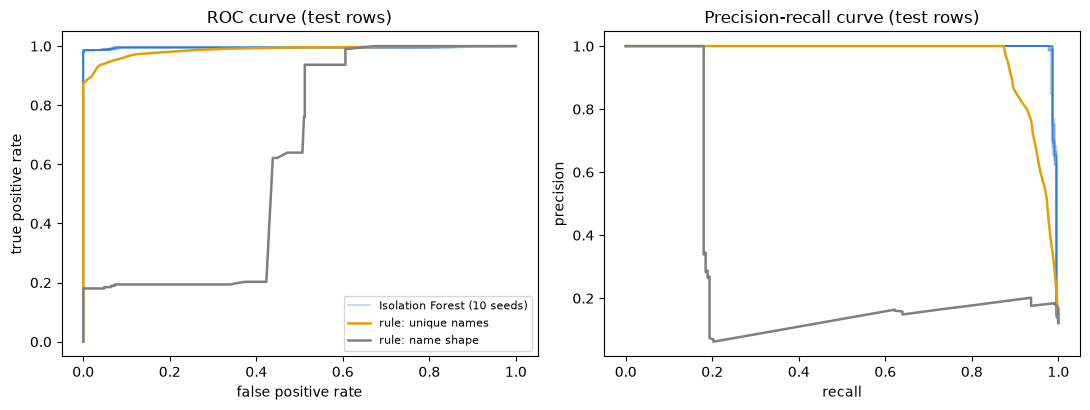

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))


def add_curves(t, label=None, **kw):
    fpr, tpr, _ = roc_curve(t.y, t.score)
    p, r, _ = precision_recall_curve(t.y, t.score)
    ax[0].plot(fpr, tpr, label=label, **kw)
    ax[1].plot(r, p, label=label, **kw)


for i, (s, (sc, _)) in enumerate(runs.items()):
    add_curves(sc[sc.role == "test"], label=f"Isolation Forest ({len(SEEDS)} seeds)" if i == 0 else None,
               color="#2a78d6", alpha=.3, lw=1.2)
for (name, sc), color in zip(rules.items(), ["#e69f00", "#7f7f7f"]):
    add_curves(sc[sc.role == "test"], label=name, color=color, lw=1.8)
ax[0].set(xlabel="false positive rate", ylabel="true positive rate", title="ROC curve (test rows)")
ax[1].set(xlabel="recall", ylabel="precision", title="Precision-recall curve (test rows)")
ax[0].legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.savefig(FIG / "roc_pr_curves.png", dpi=150)
plt.show()
plt.close(fig)

### Summary: ROC and Precision-Recall Curves

The ROC and Precision-Recall curves compare Isolation Forest with two rule-based detection methods.

Isolation Forest achieves the best overall performance, with a ROC AUC of 0.996 and a PR AUC of 0.993. The unique-name rule also performs well, while the name-shape rule is considerably less effective.

The curves show that Isolation Forest can distinguish tunnel queries from benign traffic very effectively across different detection thresholds.

However, at the selected alert threshold, the model still generates 71 false positives while detecting 219 of the 222 tunnel queries.

This suggests that threshold calibration may help reduce false positives while maintaining high recall. Any threshold adjustments must be validated without using the final test labels.

## 3. The alerts as incidents

Hundreds of alert queries are not hundreds of things to investigate. Alerts of the same client and domain less than 60 seconds apart form one incident (`src/incidents.py`).

In [16]:
inc0 = group_alerts(scored0).assign(
    start=lambda d: pd.to_datetime(d.start, unit="s").dt.strftime("%H:%M:%S"),
    end=lambda d: pd.to_datetime(d.end, unit="s").dt.strftime("%H:%M:%S"))
print("incidents of seed 0:")
display(inc0.round(3))

INC = ["fp", "incidents", "false_incidents", "tunnel_incidents", "false_incidents_per_hour", "seconds_to_first_alert"]
rows = {f"Isolation Forest (mean of {len(SEEDS)} seeds)": main[INC].astype(float).mean()}
for name, sc in rules.items():
    rows[name] = pd.Series(metrics(sc))[INC]
pd.DataFrame(rows).T.astype(float).round(2).rename(columns={"fp": "false alert queries"})

incidents of seed 0:


,client,parent,start,end,alerts,top_score,is_tunnel
0,192.168.179.21,azure.com,18:42:13,18:42:13,1,0.688,False
1,192.168.179.21,azure.com,18:46:42,18:47:17,3,0.691,False
2,192.168.179.21,azure.com,18:49:56,18:49:56,1,0.682,False
3,192.168.179.21,yahoo.com,18:50:29,18:52:00,55,0.717,False
4,10.0.2.30,pirate.sea,18:50:50,18:51:15,219,0.801,True
5,192.168.179.21,yahoodns.net,18:51:04,18:52:00,10,0.695,False
6,192.168.179.21,azure.com,19:04:42,19:04:42,1,0.688,False


,false alert queries,incidents,false_incidents,tunnel_incidents,false_incidents_per_hour,seconds_to_first_alert
Isolation Forest (mean of 10 seeds),75.6,4.6,3.6,1.0,5.41,0.01
rule: unique names,52.0,2.0,1.0,1.0,1.50,3.02
rule: name shape,4.0,3.0,2.0,1.0,3.01,0.01


### Summary: Incident-Level Evaluation

The incident-level analysis shows how individual DNS alerts are grouped into security incidents.

For seed 0, Isolation Forest generates 71 false-positive queries across six false incidents. Most false alerts originate from `yahoo.com` (55) and `yahoodns.net` (10), while Azure generates six false alerts across four incidents.

The 219 detected tunnel queries are grouped into one incident, with a maximum anomaly score of 0.801.

Across ten seeds, Isolation Forest produces an average of 3.6 false incidents, compared with one for the unique-name rule.

This shows that Isolation Forest provides stronger query-level detection but creates a higher operational alert burden.

Potential improvements include training-based threshold calibration, better incident aggregation, and incident prioritisation. These changes require further validation to avoid reducing tunnel detection performance.

## 4. Check 1: the alert line and the window

The ranking hardly changes with the window or the threshold method, but the number of false positives does. Mean over seeds of the false positives and the recall for every combination. `folds_median` at 60 s is the default; the others are for comparison, not for choosing on these test rows.

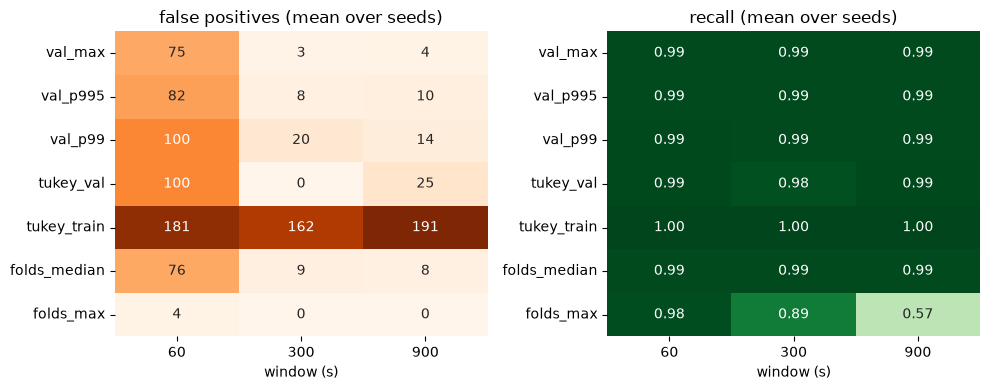

ranking (mean over seeds and thresholds), per window:


,roc_auc,pr_auc
window,,
60,0.996,0.993
300,0.996,0.993
900,0.997,0.995


In [17]:
THRESHOLDS = ["val_max", "val_p995", "val_p99", "tukey_val", "tukey_train", "folds_median", "folds_max"]
rows = []
for w in (60, 300, 900):
    mw = make_matrix(session="second", window_s=w, write=False)
    fw = feature_sets(w)["forced"]
    for s in SEEDS:
        sc, info = run_detector(mw, fw, random_state=s)
        t = sc[sc.role == "test"]
        for th in THRESHOLDS:
            cc = confusion(t.y, t.score > info["candidates"][th])
            rows.append({"window": w, "threshold": th, "seed": s, "fp": cc["fp"], "recall": cc["recall"],
                         "roc_auc": roc_auc_score(t.y, t.score), "pr_auc": average_precision_score(t.y, t.score)})
sens = pd.DataFrame(rows)
fp_mean = sens.pivot_table(index="threshold", columns="window", values="fp").reindex(THRESHOLDS)
fp_sd = sens.pivot_table(index="threshold", columns="window", values="fp", aggfunc="std").reindex(THRESHOLDS)
rec_mean = sens.pivot_table(index="threshold", columns="window", values="recall").reindex(THRESHOLDS)

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
sns.heatmap(fp_mean, annot=True, fmt=".0f", cmap="Oranges", ax=ax[0], cbar=False)
ax[0].set_title("false positives (mean over seeds)")
sns.heatmap(rec_mean, annot=True, fmt=".2f", cmap="Greens", vmin=0.4, vmax=1, ax=ax[1], cbar=False)
ax[1].set_title("recall (mean over seeds)")
for a in ax:
    a.set_ylabel(""); a.set_xlabel("window (s)")
plt.tight_layout(); plt.savefig(FIG / "threshold_by_window.png", dpi=150); plt.show()
print("ranking (mean over seeds and thresholds), per window:")
sens.groupby("window")[["roc_auc", "pr_auc"]].mean().round(3)

### Summary: Threshold Calibration and Window Size

This experiment evaluates how different alert thresholds and observation windows affect DNS tunnel detection.

The original configuration, using `folds_median` with a 60-second window, produces approximately 76 false positives with a recall of 0.99.

Using `val_max` with a 300-second window reduces false positives to approximately three while maintaining a recall of about 0.99.

More conservative thresholds, such as `folds_max`, can eliminate false positives but substantially reduce recall.

ROC AUC and PR AUC remain consistently high across the three window sizes, indicating that the model's ranking ability is relatively stable.

These results suggest that threshold calibration offers a major opportunity to reduce false positives without significantly reducing detection performance.

However, the best-performing configuration cannot be selected solely from test results. The threshold calculation, detection delay, and generalisation to independent traffic must be verified before changing the default configuration.

In [18]:
print("mean over seeds: false positives and recall per alert line and window")
display(pd.concat({"false positives": fp_mean.round(0), "recall": rec_mean.round(3)}, axis=1))
print("spread of the false positives over seeds (standard deviation):")
fp_sd.round(1)

mean over seeds: false positives and recall per alert line and window


false positives               recall              
window                   60     300    900    60     300    900
threshold                                                      
val_max                 75.0    3.0    4.0  0.987  0.986  0.986
val_p995                82.0    8.0   10.0  0.987  0.986  0.986
val_p99                100.0   20.0   14.0  0.989  0.986  0.986
tukey_val              100.0    0.0   25.0  0.991  0.977  0.989
tukey_train            181.0  162.0  191.0  0.995  0.995  0.995
folds_median            76.0    9.0    8.0  0.987  0.986  0.986
folds_max                4.0    0.0    0.0  0.983  0.889  0.571

spread of the false positives over seeds (standard deviation):


window,60,300,900
threshold,,,
val_max,11.7,2.7,2.4
val_p995,11.2,4.5,5.4
val_p99,7.3,12.9,4.5
tukey_val,11.2,0.0,11.6
tukey_train,9.3,7.6,8.4
folds_median,9.7,4.8,2.7
folds_max,8.1,0.0,0.0


### Summary: False Positive Variability Across Seeds

The analysis evaluates the stability of false-positive counts across ten Isolation Forest random seeds.

The original configuration (folds_median, 60 seconds) produces an average of 76 false positives with a standard deviation of 9.7.

Using val_max with a 300-second window reduces this to an average of three false positives, with a standard deviation of 2.7, while maintaining a recall of 0.986.

The tukey_val configuration with a 300-second window produces zero false positives across all ten seeds, but recall decreases to 0.977.

These findings suggest that val_max with a 300-second window offers a promising balance between detection performance and false positives.

However, stability across random seeds does not establish generalisation to new network traffic. Independent validation and incident-level evaluation are still required before selecting a final configuration.

### The alert line depends on which piece of training you hold back

Each of the five consecutive pieces of the training period is held back in turn: a forest is fitted on the other four, and the highest score of the held-back piece becomes the line, which is then applied to the test rows. The default (`folds_median`) is the median of these five lines, `folds_max` the highest, `val_max` the last piece only. We fixed this rule before looking at the test rows; the table is there to show the spread, not to pick the best piece. Mean of 5 seeds.

In [19]:
from sklearn.metrics import roc_auc_score, average_precision_score
from src.detector import fit_forest, anomaly_score

tr = m[m.split == "train"].sort_values("ts", kind="mergesort")
te = m[m.split == "test"]
blocks = np.array_split(np.arange(len(tr)), 5)
rows = []
for i, idx in enumerate(blocks):
    held, rest = tr.iloc[idx], tr.drop(tr.index[idx])
    for s in SEEDS[:5]:
        mod = fit_forest(rest[FEATURES], random_state=s)
        line = anomaly_score(mod, held[FEATURES]).max()
        sc = anomaly_score(mod, te[FEATURES])
        cc = confusion(te.y.values, (sc > line).astype(int))
        rows.append({"held-back piece": i + 1, "line": line, "roc_auc": roc_auc_score(te.y, sc),
                     "pr_auc": average_precision_score(te.y, sc), "recall": cc["recall"],
                     "precision": cc["precision"], "fp": cc["fp"]})
folds = pd.DataFrame(rows).groupby("held-back piece").mean().round(3)
display(folds)
print(f"line ranges from {folds.line.min():.3f} to {folds.line.max():.3f}; false positives from {folds.fp.min():.0f} to {folds.fp.max():.0f}; "
      f"ROC AUC stays {folds.roc_auc.min():.3f} to {folds.roc_auc.max():.3f}")

,line,roc_auc,pr_auc,recall,precision,fp
held-back piece,,,,,,
1,0.711,0.996,0.994,0.985,0.985,3.4
2,0.677,0.995,0.993,0.987,0.718,86.4
3,0.671,0.996,0.993,0.987,0.744,76.0
4,0.610,0.996,0.993,0.995,0.604,145.0
5,0.675,0.996,0.993,0.987,0.747,75.0


line ranges from 0.610 to 0.711; false positives from 3 to 145; ROC AUC stays 0.995 to 0.996


### Summary: Threshold Stability Across Validation Folds

The analysis shows that alert threshold calibration is sensitive to the selected validation fold.

Thresholds range from 0.610 to 0.711, resulting in approximately 3 to 145 false positives.

Despite these differences, ROC AUC remains between 0.995 and 0.996, while PR AUC stays between 0.993 and 0.994.

This demonstrates that strong ranking performance does not guarantee stable operational detection performance.

The main challenge is therefore not necessarily improving the Isolation Forest model, but selecting a robust and reproducible alert threshold.

Further investigation should examine differences between validation folds and evaluate threshold calibration methods using only training and validation data, without optimising on the final test set.

## 5. Check 2: robustness and stress tests

The same model and settings (60 s, `folds_median`, 5 seeds) on other versions of the data, next to the unique-names rule. The simulations are built from this one capture (`src/variants.py`); they test robustness, they do not prove generalisation.

- **strict:** the other copy of the tunnel session, with only 244 quiet rows to train on (a load change between training and test)
- **slow tunnel:** the same queries, 20 or 60 times further apart (60 times is about 25 minutes)
- **10 benign hosts:** the normal traffic copied onto more hosts that share domains
- **one repeated tunnel name:** a retransmission, or an attacker repeating a name

In [20]:
STRESS_SEEDS = SEEDS[:5]
prep = prepare(load_raw(), session="second")
cases = {
    "main (reference)": m,
    "strict: other copy, 244 training rows": make_matrix(session="first", window_s=WINDOW, write=False),
    "slow tunnel x20": build_features(slow_tunnel(prep, 20), WINDOW),
    "slow tunnel x60": build_features(slow_tunnel(prep, 60), WINDOW),
    "10 benign hosts": build_features(add_benign_clients(prep, n_extra=9, seed=0), WINDOW),
    "one repeated tunnel name": build_features(inject_repeats(prep, n=1), WINDOW),
}
RCOLS = ["roc_auc", "pr_auc", "precision", "recall", "fp", "false_incidents", "seconds_to_first_alert"]
rows = []
for name, mc in cases.items():
    ms = pd.DataFrame([metrics(run_detector(mc, FEATURES, threshold=THRESHOLD, random_state=s)[0]) for s in STRESS_SEEDS])
    rows.append({"case": name, "model": "Isolation Forest", **ms[RCOLS].astype(float).mean().to_dict()})
    rows.append({"case": name, "model": "rule: unique names", **pd.Series(metrics(run_rule(mc, "unique_names", WINDOW)))[RCOLS].astype(float).to_dict()})
robust = pd.DataFrame(rows).set_index(["case", "model"]).round(3)
robust

roc_auc  pr_auc  precision  recall     fp  false_incidents  seconds_to_first_alert
case                                  model                                                                                                 
main (reference)                      Isolation Forest      0.996   0.993      0.741   0.987   77.0              4.0                   0.007
                                      rule: unique names    0.987   0.958      0.798   0.928   52.0              1.0                   3.016
strict: other copy, 244 training rows Isolation Forest      0.992   0.983      0.247   0.986  669.2             45.6                   0.007
                                      rule: unique names    0.989   0.954      0.301   0.982  506.0             30.0                   0.007
slow tunnel x20                       Isolation Forest      0.995   0.989      0.740   0.983   77.0              4.0                   0.144
                                      rule: unique names    0.953   0.874      0.772   0.793   52.0              1.0                 261.984
slow tunnel x60                       Isolation Forest      0.995   0.989      0.740   0.983   77.0              4.0                   0.433
                                      rule: unique names    0.931   0.861      0.772   0.793   52.0              1.0                 785.952
10 benign hosts                       Isolation Forest      0.996   0.988      0.432   0.986  379.0             19.2                   0.007
                                      rule: unique names    0.987   0.906      0.284   0.928  520.0             10.0                   3.016
one repeated tunnel name              Isolation Forest      0.996   0.993      0.742   0.987   77.0              4.0                   0.007
                                      rule: unique names    0.987   0.958      0.799   0.928   52.0              1.0                   3.016

### Summary: Robustness and Stress Testing

The robustness experiments evaluate Isolation Forest under different training and traffic conditions.

Isolation Forest maintains high recall across all tested scenarios, ranging from 0.983 to 0.987.

However, the strict training scenario reveals a major limitation. With only 244 benign training queries, precision drops to 0.247 and false positives increase to approximately 669.

The slow-tunneling experiments show that Isolation Forest maintains a recall of 0.983 under both 20× and 60× slowdown, while the unique-name rule drops to 0.793.

Increasing the number of benign hosts also increases false positives and false incidents, highlighting the importance of operational scalability.

Repeating one tunnel name has almost no effect on detection performance, although this is only a limited robustness test.

Overall, Isolation Forest demonstrates strong detection capability, but its operational reliability depends on representative training data and effective false-positive control.

Further validation should verify the stress-test methodology and evaluate whether the promising 300-second window and alternative threshold calibration remain effective under these conditions.

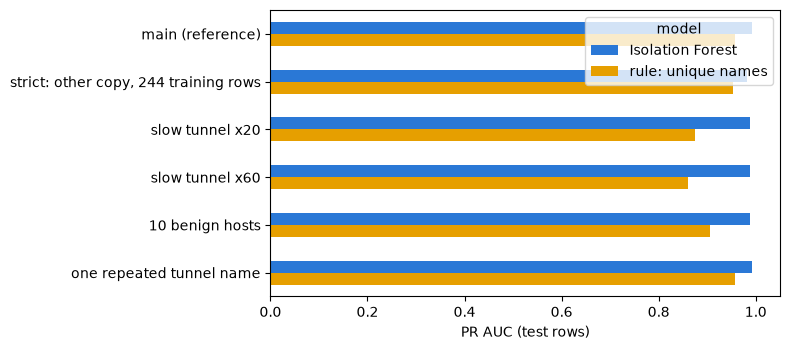

In [21]:
pr = robust["pr_auc"].unstack("model").loc[list(cases)]
fig, ax = plt.subplots(figsize=(8, 3.6))
pr.plot.barh(ax=ax, color=["#2a78d6", "#e69f00"]); ax.invert_yaxis()
ax.set_xlabel("PR AUC (test rows)"); ax.set_ylabel(""); ax.set_xlim(0, 1.05)
plt.tight_layout(); plt.savefig(FIG / "stress_tests_pr_auc.png", dpi=150); plt.show()

### Summary: PR AUC Across Stress Scenarios

Isolation Forest consistently outperforms the unique-name rule across all six stress scenarios.

Its PR AUC remains between 0.983 and 0.993, demonstrating strong ranking performance under different training and traffic conditions.

The largest advantage appears in the slow-tunneling scenarios, where the unique-name rule loses substantial performance while Isolation Forest remains relatively stable.

However, high PR AUC does not guarantee good operational performance at a fixed alert threshold. The strict training scenario still produces a large number of false positives.

These results support Isolation Forest as the stronger detection method, while highlighting the importance of representative training data and robust threshold calibration.

## 6. Check 3: the errors

Which normal queries raise alerts, and which tunnel queries are missed (seed 0, default alert line).

In [22]:
def clock(ts):
    d = pd.to_datetime(ts, unit="s")
    return d.dt.strftime("%H:%M:%S") if isinstance(d, pd.Series) else d.strftime("%H:%M:%S")


fp = t0[(t0.alert == 1) & (t0.y == 0)]
print(f"{len(fp)} false alert queries; per domain:")
print(fp.parent.value_counts().to_string())
train_part = scored0[scored0.role != "test"]
normal_test = t0[t0.y == 0]
print(f"\nlargest unique-names count in training: {train_part.uniq_names_60s.max():.0f}; "
      f"normal test rows above it: {(normal_test.uniq_names_60s > train_part.uniq_names_60s.max()).sum()}")
print(f"false alerts between {clock(fp.ts.min())} and {clock(fp.ts.max())} UTC; "
      f"{(fp.parent == 'yahoo.com').sum()} of them are yahoo.com")

show = ["time", "parent", "score"] + FEATURES
print("\ntop 10 false alerts:")
display(fp.assign(time=clock(fp.ts)).sort_values("score", ascending=False).head(10)[show].round(3))
fn = t0[(t0.alert == 0) & (t0.y == 1)]
print("missed tunnel queries:")
display(fn.assign(time=clock(fn.ts))[["time", "phase", "score"] + FEATURES].round(3))

71 false alert queries; per domain:
parent
yahoo.com       55
yahoodns.net    10
azure.com        6

largest unique-names count in training: 16; normal test rows above it: 52
false alerts between 18:42:13 and 19:04:42 UTC; 55 of them are yahoo.com

top 10 false alerts:


,time,parent,score,name_bytes,uniq_names_60s,uniq_ratio_60s,norepeat_tol
1949,18:50:30,yahoo.com,0.717,34,25.0,0.255,0.881
1948,18:50:30,yahoo.com,0.717,34,25.0,0.258,0.889
1950,18:50:30,yahoo.com,0.717,34,25.0,0.253,0.873
2351,18:51:03,yahoo.com,0.708,13,27.0,0.241,0.851
1935,18:50:30,yahoo.com,0.705,13,24.0,0.258,0.882
1934,18:50:30,yahoo.com,0.704,13,24.0,0.261,0.891
1933,18:50:30,yahoo.com,0.704,13,24.0,0.264,0.900
2019,18:50:33,yahoo.com,0.703,14,26.0,0.241,0.843
1905,18:50:29,yahoo.com,0.702,30,20.0,0.263,0.860
1906,18:50:29,yahoo.com,0.702,30,20.0,0.260,0.850


missed tunnel queries:


,time,phase,score,name_bytes,uniq_names_60s,uniq_ratio_60s,norepeat_tol
2246,18:50:50,handshake,0.408,22,1.0,1.0,0.693
2247,18:50:50,handshake,0.644,43,2.0,1.0,1.099
2248,18:50:50,encoding_test,0.661,17,3.0,1.0,1.386


### Summary: False Positive and False Negative Analysis

The error analysis identifies two main patterns.

First, false positives are strongly concentrated in legitimate Yahoo-related DNS traffic. Of the 71 false alerts, 65 originate from `yahoo.com` and `yahoodns.net`.

The training data contain a maximum of 16 unique DNS names within 60 seconds, while some benign test queries reach 27. This suggests that the training data do not fully represent legitimate high-volume DNS behaviour.

Second, the three missed tunnel queries occur during the initial handshake and encoding-test phases. At this point, only one to three unique DNS names have been observed, providing limited behavioural evidence.

The model subsequently detects the remaining 219 tunnel queries.

These findings suggest two improvement priorities: better representation of legitimate DNS behaviour to reduce false positives, and investigation of additional signals for earlier tunnel detection.

Both improvements should be validated without introducing domain-specific shortcuts or test-data leakage.

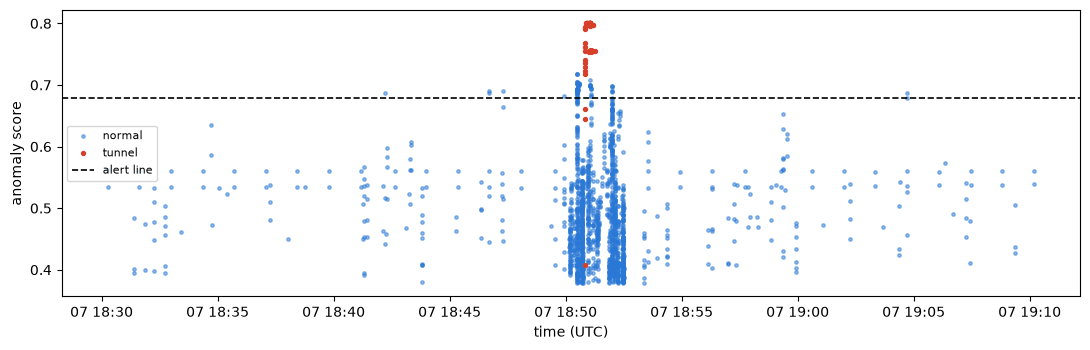

In [23]:
tt = t0.assign(dt=pd.to_datetime(t0.ts, unit="s"))
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.scatter(tt[tt.y == 0].dt, tt[tt.y == 0].score, s=6, c="#2a78d6", alpha=.5, label="normal")
ax.scatter(tt[tt.y == 1].dt, tt[tt.y == 1].score, s=8, c="#d6402a", label="tunnel")
ax.axhline(info0["threshold"], color="k", ls="--", lw=1.2, label="alert line")
ax.set_ylabel("anomaly score"); ax.set_xlabel("time (UTC)"); ax.legend(fontsize=8, loc="center left")
plt.tight_layout(); plt.savefig(FIG / "score_timeline.png", dpi=150); plt.show()

### Summary: Anomaly Scores Over Time

The timeline shows that Isolation Forest successfully separates most DNS tunnel queries from normal traffic.

Tunnel activity is concentrated around 18:50–18:51 UTC, with most anomaly scores exceeding the alert threshold of approximately 0.68.

Some legitimate DNS queries also exceed the threshold, producing false positives. Previous analysis identified Yahoo-related traffic as the main contributor.

The first three tunnel queries remain below the threshold, indicating that the model requires some behavioural evidence before detecting the tunnel.

Overall, the timeline confirms strong detection performance while highlighting two limitations: false positives during legitimate DNS activity and missed queries during tunnel initiation.

Further investigation should focus on threshold calibration and verification of the reported detection delay.

## 7. Takeaways

**The main result (section 1, default setup, mean over 10 seeds).**
- The tunnel is ranked almost perfectly: ROC AUC 0.996 and PR AUC 0.993, with almost no spread between seeds.
- At the default alert line recall is 0.987. Only the first 2 to 3 queries of the session are missed (handshake and encoding-test queries; seed 0 misses 3); the first alert comes 7 milliseconds into the session. Precision is 0.744 (0.69 to 0.77 over seeds) and F1 0.848, with 76 false alert queries on average (64 to 97). The alert line is the median of five lines, one per held-back piece of training; it was chosen before looking at the test rows.
- Grouped into incidents (section 3), the tunnel is one incident of 219 alerts and the false alerts are about 4 incidents (3 to 6 over seeds; seed 0 has 6: `yahoo.com` 55 alerts, `yahoodns.net` 10 and four short `azure.com` ones with 6 alerts together).
- The model leans on `uniq_names_60s` (PR AUC drop 0.342 when shuffled) and `norepeat_tol` (0.200). `name_bytes` (0.007) and `uniq_ratio_60s` (0.004) hardly matter here.

**Against simple rules (section 2).**
- A rule on unique names alone is competitive at its operating point: F1 0.858 against 0.848, precision 0.798, recall 0.928, and only 1 false incident. The forest ranks better (PR AUC 0.993 against 0.958) and misses less (recall 0.987).
- A rule on name length or randomness finds only the data and probe queries (recall 0.18, ROC AUC 0.617), which confirms that single-query checks are not enough.

**Where the forest is clearly better: slow tunnels (section 5).** With the tunnel 60 times slower (about 25 minutes), the forest keeps PR AUC 0.989 and alerts within 0.5 seconds of the session start, because `norepeat_tol` has no time window. The unique-names rule falls to recall 0.793 and needs 262 to 786 seconds to alert.

**What the alert line does (sections 4 and 6).**
- The line depends on which piece of training is held back: across the five pieces it ranges from 0.61 to 0.71 and the false positives from about 3 to 145, while ROC AUC stays 0.995 to 0.996. The ranking is stable; the line is the fragile part. We use the median of the five and show the spread; we did not pick the piece that gives the fewest false alerts.
- The ranking does not depend on the window (PR AUC 0.993, 0.993, 0.995 for 60, 300 and 900 s), but the number of false positives does: with `folds_median` 76 at 60 s against 9 and 8 at 300 and 900 s. The `folds_max` line looks best at 60 s (4 false positives) but loses recall at longer windows (0.889 at 300 s, 0.571 at 900 s). Do not choose a window or an alert line because of these counts: they were seen on the test rows.
- The false alerts come from one busy normal period: 55 of the 71 false alert queries of seed 0 are `yahoo.com` between 18:50 and 18:52. Training never saw more than 16 unique names in 60 s, and 52 normal test rows exceed that. The detector has no way to know that this burst is normal; this is the main limit of a model trained on a short, calm period of normal traffic.

**Robustness (section 5).** With only 244 quiet training rows (strict variant) the alert line is far too low: about 670 false positives (precision 0.25), while the ranking holds (PR AUC 0.983). With 10 benign hosts there are about 19 false incidents and precision falls to 0.43. A repeated tunnel name changes nothing.

**What this does not show.** One tunnel session and one benign client, so all numbers are optimistic and say nothing about other tunnels or networks. The variants are simulations built from this one capture. The seeds vary the random forest only, not the data. Comparing alert lines on the test rows was done to explain the results, not to choose the default. Not covered: tunnels that rotate domains, tunnels with other record types, a second dataset, and a live setting where normal traffic changes over time and the alert line needs recalibrating.

**One sentence.** DNS tunnelling is found because it cannot avoid creating many new names under one domain; the Isolation Forest ranks it almost perfectly from a few such features, and how many false alerts result depends on the alert line and on how representative the normal training traffic is.
